### Grad-Cam explainability for our CNN models

In [27]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

In [28]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf

from src.datasets import create_datasets, class_names

In [29]:
train_ds, val_ds, test_ds = create_datasets()

Found 4200 files belonging to 2 classes.
Found 900 files belonging to 2 classes.
Found 900 files belonging to 2 classes.


In [4]:
models_path = Path("./models")

small_model = tf.keras.models.load_model(
    models_path / "ai_capstone_keras_best_small_model.keras"
)

print(small_model.summary())

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64, 64, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_8 (ReLU)                  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_9 (ReLU)                  │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 319,400 (1.22 MB)

 Trainable params: 106,306 (415.26 KB)

 Non-trainable params: 480 (1.88 KB)

 Optimizer params: 212,614 (830.53 KB)

None


In [5]:
img_size = (64,64)
last_conv_layer_name = "re_lu_8"

small_model.build((None, 64, 64, 3))

print(small_model.built)
print(small_model.input_shape)
print(small_model.output_shape)

True
(None, 64, 64, 3)
(None, 2)


In [6]:
## a symbolic call of the model to define the outputs 

inputs = tf.keras.Input(shape=(64, 64, 3))
predictions = small_model(inputs)

print(predictions.shape)

(None, 2)


### 01. Manually implement the Grad-Cam heatmap

In [7]:
def make_gradcam_heatmap(
    image,
    grad_model,
    class_index=None
):
    image = tf.cast(image, tf.float32)

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(
            image, training=False
        )

        if class_index is None:
            class_index = tf.argmax(predictions[0])

        class_score = predictions[:, class_index]

    grads = tape.gradient(class_score, conv_outputs)

    # Average gradients spatially to obtain channel weights.
    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)

    # Combine feature maps using their weights.
    heatmap = tf.reduce_sum(weights * conv_outputs, axis=-1)

    # Keep positive contributions and normalize.
    heatmap = tf.nn.relu(heatmap)
    heatmap = heatmap / (
        tf.reduce_max(heatmap, axis=(1, 2), keepdims=True) + 1e-8
    )

    return heatmap[0].numpy()

In [8]:
## take one batch and the first image of it with shape (1, H, W, C)
images, labels = next(iter(test_ds))

image = images[0:1]

# Convert 0–255 float32 -> uint8 # for displaying original image
image_unnormalized = np.clip(image[0], 0, 255).astype(np.uint8)


In [9]:
inputs = tf.keras.Input(shape=(64, 64, 3))
x = inputs
conv_outputs = None

for layer in small_model.layers:
    x = layer(x)

    if layer.name == "re_lu_8":
        conv_outputs = x

predictions = x

grad_model = tf.keras.Model(
    inputs=inputs,
    outputs=[conv_outputs, predictions]
)

heatmap = make_gradcam_heatmap(
    image,
    grad_model
)

W0000 00:00:1791970985.279437    1277 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1791970985.298190    1277 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1791970985.323183    1277 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1791970985.325927    1277 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1791970985.327440    1277 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1791970985.330249    1277 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1791970985.331790    1277 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1791970985.333325    1277 gpu_timer.cc:114] Skipping the delay kernel, measurement accuracy will be reduced
W0000 00:00:1791970985.334836    1277 gp

In [10]:

conv_values, predictions = grad_model(
    image,
    training=False
)

print(conv_values.shape)
print(predictions.shape)

(1, 8, 8, 128)
(1, 2)


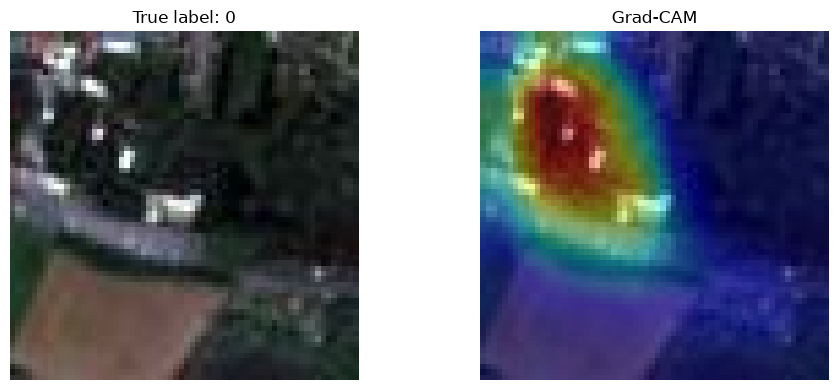

In [11]:
heatmap_resized = tf.image.resize(
    heatmap[..., np.newaxis],
    size=(64, 64)
).numpy().squeeze()


fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(image_unnormalized)
axes[0].set_title(f"True label: {labels[0].numpy()}")

axes[1].imshow(image_unnormalized)
axes[1].imshow(
    heatmap_resized,
    cmap="jet",
    alpha=0.4,
    vmin=0,
    vmax=1
)
axes[1].set_title("Grad-CAM")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()